<div align="center">

# Challenge 2 · Pipeline de Machine Learning

**Infecciones Respiratorias Agudas (IRA) y neumonía en menores de 5 años en el Perú**

*Búsqueda de estados (IA) · Predicción con regresión lineal (Machine Learning)*

</div>

---

**Fuente:** [Ministerio de Salud del Perú (MINSA), 23 de junio de 2025](https://www.gob.pe/institucion/minsa/noticias/1192975).

> **Cómo leer los datos:** **SE 24** significa **semana epidemiológica 24**, un periodo usado para registrar y comparar enfermedades. Las cifras de 2023, 2024 y 2025 corresponden a periodos equivalentes hasta esa semana; **no son totales de años completos**. En 2025 el corte fue el 15 de junio.

| Pipeline | Propósito | Método |
|:--|:--|:--|
| **1. Razonamiento y búsqueda** | Representar y recorrer acciones de atención y prevención | Búsqueda en amplitud (**BFS**) |
| **2. Predicción y visualización** | Ilustrar la tendencia de defunciones reportadas | **Regresión lineal** |


## 1. Pipeline de razonamiento, búsqueda y resultados

### 1.1. Problema

**Situación inicial:** alta presencia de IRA y neumonía en menores de cinco años.  
**Objetivo:** llegar a una situación de reducción de casos y defunciones mediante una **secuencia conceptual** de acciones sanitarias.

Este ejercicio utiliza **Inteligencia Artificial (IA)** para representar estados y recorrer sus conexiones. No pretende demostrar que una acción cause una reducción de enfermedades.

### 1.2. Librería utilizada

`deque` permite trabajar con una **cola FIFO** (*primero en entrar, primero en salir*), utilizada por la búsqueda BFS.


In [1]:
from collections import deque

### 1.3. Estados

Un **estado** representa una situación del problema. Se mantienen los seis estados definidos en el caso:

| Código | Estado | Papel |
|:--:|:--|:--|
| **E0** | Alta presencia de IRA y neumonía | **Inicial** |
| **E1** | Vacunación y campañas preventivas | Intermedio |
| **E2** | Detección y vigilancia | Intermedio |
| **E3** | Atención médica y tratamiento | Intermedio |
| **E4** | Seguimiento y control sanitario | Intermedio |
| **E5** | Reducción de casos y defunciones | **Objetivo** |

**Representación visual del recorrido:**

**E0 → E1 → E2 → E3 → E4 → E5**

Las **transiciones** representan acciones como prevenir, detectar, atender y hacer seguimiento. En el código se utilizan las descripciones completas de los estados; los códigos E0–E5 son sus identificadores abreviados.

**Restricciones:** el caso no aporta tasas reales de cobertura de vacunación, datos regionales ni evidencia suficiente para establecer causalidad. Por ello, los estados constituyen un modelo simplificado.


In [2]:
espacio_estados = {
    "Alta presencia de IRA y neumonía":
        ["Vacunación y campañas preventivas"],

    "Vacunación y campañas preventivas":
        ["Detección y vigilancia"],

    "Detección y vigilancia":
        ["Atención médica y tratamiento"],

    "Atención médica y tratamiento":
        ["Seguimiento y control sanitario"],

    "Seguimiento y control sanitario":
        ["Reducción de casos y defunciones"],

    "Reducción de casos y defunciones":
        []
}

# Estado inicial
estado_inicial = "Alta presencia de IRA y neumonía"

# Estado objetivo
estado_objetivo = "Reducción de casos y defunciones"

print("Estado inicial:", estado_inicial)
print("Estado objetivo:", estado_objetivo)

Estado inicial: Alta presencia de IRA y neumonía
Estado objetivo: Reducción de casos y defunciones


### 1.4. Exploración y búsqueda BFS

**Exploración:** el algoritmo revisa las conexiones de cada estado y utiliza la lista `visitados` para evitar recorrer repetidamente el mismo estado.

**Búsqueda:** **BFS** (*Breadth-First Search*, o **búsqueda en amplitud**) extrae caminos de una cola y explora sus sucesores hasta encontrar el estado objetivo.

En este problema solo existe una ruta posible, por lo que BFS **no compara estrategias sanitarias alternativas**.


In [3]:
def bfs(espacio_estados, estado_inicial, estado_objetivo):

    cola = deque([[estado_inicial]])
    visitados = []

    while cola:
        camino = cola.popleft()
        estado_actual = camino[-1]

        if estado_actual == estado_objetivo:
            return camino

        if estado_actual not in visitados:
            visitados.append(estado_actual)

            for siguiente_estado in espacio_estados[estado_actual]:
                nuevo_camino = camino + [siguiente_estado]
                cola.append(nuevo_camino)

    return None

resultado = bfs(
    espacio_estados,
    estado_inicial,
    estado_objetivo
)

print("Camino encontrado:")

for estado in resultado:
    print("->", estado, end=' ')

Camino encontrado:
-> Alta presencia de IRA y neumonía -> Vacunación y campañas preventivas -> Detección y vigilancia -> Atención médica y tratamiento -> Seguimiento y control sanitario -> Reducción de casos y defunciones 

### 1.5. Resultado e interpretación

El algoritmo encuentra el recorrido desde el estado inicial hasta el objetivo:

**E0 → E1 → E2 → E3 → E4 → E5**

| Resultado | Interpretación |
|:--|:--|
| Ruta encontrada | Se visitan las etapas de prevención, vigilancia, atención y seguimiento. |
| Alcance | Es una **ruta conceptual**, no una intervención implementada ni una prueba de eficacia clínica. |


---

## 2. Pipeline de predicción y visualización

### 2.1. Problema y librerías

Se busca representar la tendencia de las **defunciones por neumonía en menores de cinco años** y calcular una **estimación ilustrativa** para el mismo periodo de 2026 (hasta SE 24).

- **NumPy:** organiza los datos numéricos.
- **Scikit-learn:** ajusta el modelo de regresión lineal.
- **Matplotlib:** presenta los datos y la recta estimada en una gráfica.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

### 2.2. Datos

Se utilizan **tres observaciones reales**, procedentes del material del caso y de la noticia del MINSA. No se agregan datos sintéticos.

| Año | Defunciones por neumonía hasta SE 24 |
|:--:|--:|
| 2023 | 113 |
| 2024 | 82 |
| 2025 | 51 |

- **Variable de entrada (`X`):** año.
- **Variable de salida (`y`):** número de defunciones reportadas hasta la semana epidemiológica 24.


In [5]:
anios = np.array([2023, 2024, 2025]).reshape(-1, 1)
defunciones = np.array([113, 82, 51])

print("Años:", anios.flatten())
print("Defunciones:", defunciones)

Años: [2023 2024 2025]
Defunciones: [113  82  51]


### 2.3. Modelo y entrenamiento

Se utiliza **regresión lineal**, un modelo de **aprendizaje supervisado** que ajusta una recta a ejemplos con valores conocidos.

**Justificación:** permite visualizar y calcular de forma sencilla una tendencia con los datos disponibles. Su uso aquí es **educativo**: tres observaciones son insuficientes para obtener un pronóstico epidemiológico confiable.


In [6]:
modelo = LinearRegression()
modelo.fit(anios, defunciones)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


### 2.4. Estimación para 2026

El modelo prolonga la tendencia observada y calcula una estimación para **el periodo equivalente hasta SE 24 de 2026**, no para el año completo.

> El texto que imprime el código dice «para 2026» por simplicidad; debe interpretarse como **hasta SE 24 de 2026**.


In [7]:
anio_futuro = np.array([[2026]])
prediccion = modelo.predict(anio_futuro)

print("Predicción de defunciones para 2026:", round(prediccion[0]))

Predicción de defunciones para 2026: 20


### 2.5. Gráfica de la predicción

La visualización diferencia los **datos observados** (2023–2025), la **recta de regresión** y el **punto estimado** para 2026.


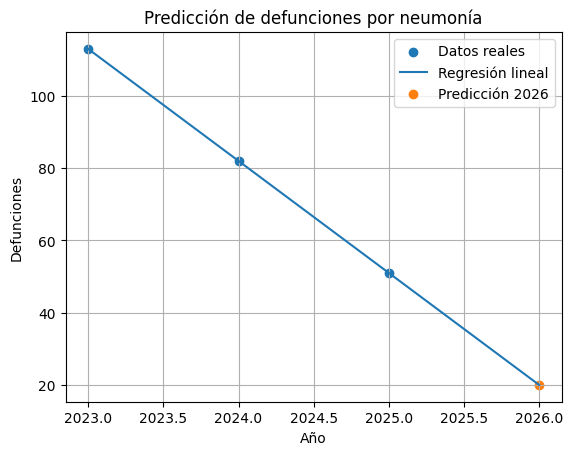

In [8]:
anios_grafica = np.array([2023, 2024, 2025, 2026]).reshape(-1, 1)

linea_prediccion = modelo.predict(anios_grafica)

plt.scatter(anios, defunciones, label="Datos reales")
plt.plot(anios_grafica, linea_prediccion, label="Regresión lineal")

plt.scatter(2026, prediccion[0], label="Predicción 2026")

plt.xlabel("Año")
plt.ylabel("Defunciones")
plt.title("Predicción de defunciones por neumonía")
plt.legend()
plt.grid()

plt.show()

### 2.6. Resultados, interpretación y limitaciones

| Resultado | Valor | Interpretación |
|:--|--:|:--|
| Defunciones observadas en 2023 | 113 | Dato del caso, hasta SE 24. |
| Defunciones observadas en 2025 | 51 | Dato del caso, hasta SE 24. |
| **Estimación para 2026** | **20** | **Extrapolación ilustrativa** para un periodo comparable. |

La tendencia presenta una reducción de **31 defunciones entre años consecutivos** en los tres puntos disponibles. Una **extrapolación** extiende ese patrón más allá de los años observados, pero no garantiza que continúe.

**Precauciones:**

- **20 no es un dato oficial de 2026 ni un pronóstico validado.**
- Solo hay tres observaciones, sin una muestra independiente para evaluar la precisión.
- El modelo no incluye vacunación, clima, regiones ni otros factores epidemiológicos; por tanto, **no permite atribuir causalidad**.

### Conclusión general

**BFS** permitió representar una ruta conceptual de acciones sanitarias. **La regresión lineal** permitió ilustrar la disminución histórica de las defunciones, con una estimación que debe interpretarse con cautela.

**Referencia principal:** Ministerio de Salud del Perú. (2025, 23 de junio). *Episodios de infecciones respiratorias agudas y muertes por neumonía en menores de 5 años disminuyen*. https://www.gob.pe/institucion/minsa/noticias/1192975


#### Archivo Original (del Examen Parcial):

**Archivo original:** [Ver notebook del examen parcial](https://github.com/Cesarapcho/Machine_Learning/blob/main/Challenge_2/Parcial_MachineLearning.ipynb).